# KPP–Fisher with position-dependent coefficients, in 1-D

This example gives the KPP–Fisher coefficients a position dependence, and shows which
coefficients each matrix element picks up and what that costs the fast assembly.

The coefficients of Eq. (3) of [arXiv:2508.01640](https://arxiv.org/pdf/2508.01640) are no longer
constants but functions of position. They take one set of values inside an interval $\mathcal R$,
the **inclusion**, and another set outside:

$$\dot u_s \;=\; D(s)\,(\Delta u)_s \;+\; Q(s)\,u_s \;+\; R(s)\,u_s^2,
\qquad
\bigl(D,Q,R\bigr)(s)=\begin{cases}(D_1,Q_1,R_1),& s\in\mathcal R,\\[2pt]
(D_0,Q_0,R_0),&\text{otherwise,}\end{cases}$$

with $(\Delta u)_s=(u_{s-1}-2u_s+u_{s+1})/h^2$, writing $s'\sim s$ for the $\pm1$ neighbours.

:::{seealso}
- [Vocabulary and symbols](../../docs/concepts.md) defines Carleman linearization (CL), bra, ket,
  acting site and the symbols $M$, $K$, $f_s$ and $h$.
- [`kpp_fisher_1d`](kpp_fisher_1d.ipynb) derives the assembly this page reuses unchanged.
:::

Two words are this page's own. A **zone** is a set of sites sharing one set of coefficients, here
$\mathcal R$ and its complement. A **key** is the label `classify_by_zone` gives a coupling, so that
couplings forced to the same value are computed once.

`find_reachable_bras` and the CL-vs-exact comparison are unchanged from
[`kpp_fisher_1d`](kpp_fisher_1d.ipynb). This notebook covers only **coefficient extraction**: which
coefficients an element picks up, and what position dependence costs the assembly.

| claim | how it works |
|---|---|
| the library takes this literally | the two zones are one `sp.Piecewise`; `M[bra, ket]` returns the acting site's coefficients |
| the fast assembly still works | one change: the key must carry each site's zone as well |

The same coefficients on a 2-D grid are in
[`kpp_fisher_position_dependent_2d`](kpp_fisher_position_dependent_2d.ipynb).


In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.sparse import csc_matrix, csr_matrix
from scipy.sparse.linalg import expm_multiply
from scipy.integrate import solve_ivp

from lin_ode.basis import CarlemanBasis, CarlemanState
from lin_ode import OperatorMatrix
from lin_ode.operators import Koopman
from lin_ode import OrdinaryDifferentialSystem
from collections.abc import Callable, Hashable, Iterator


# one set of coefficients per zone: 1 inside the box, 0 outside
D_0, D_1, Q_0, Q_1, R_0, R_1, h = sp.symbols("D_0 D_1 Q_0 Q_1 R_0 R_1 h", real=True)
u = sp.IndexedBase("u")  # field symbol; the basis supplies only the sites and powers


def coord(label):  # site label -> integer coordinate tuple (wraps the bare 1-D scalar)
    return tuple(int(v) for v in label) if isinstance(label, (sp.Tuple, tuple)) else (int(label),)


def as_monomial(*factors):  # CarlemanState((site, power), ...) -> u[site]**power * ...
    return sp.Mul(*[u[coord(site)] ** power for site, power in factors])

def in_box(site, box):  # is this coordinate tuple inside the closed box ((lo, hi), ...)?
    return all(lo <= axis_val <= hi for axis_val, (lo, hi) in zip(site, box))

StateLabel = tuple[tuple[int, int], ...]  # a state, as its (site, power) factors

ZonedFactors = tuple[tuple[tuple[int, ...], int, Hashable], ...]  # ... plus the site's zone
ZonedKey = tuple[ZonedFactors, ZonedFactors]  # (bra, ket), what classify_by_zone returns
Zone = Callable[[tuple[int, ...]], Hashable]  # a coordinate tuple to its zone label


**One `Piecewise`, two arms.** `fisher` writes the system for a grid of any dimension: `shape` gives
the sites per axis, `box` the closed index range of the inclusion along each axis.

Both arms read $D,Q,R$ at the acting site $s$, never at its neighbours.


In [2]:
def fisher(shape: tuple[int, ...], box: tuple[tuple[int, int], ...]) -> OrdinaryDifferentialSystem:
    """Fisher-KPP on a grid of `shape`, with (D, Q, R) switching to zone 1 inside `box`."""
    idx = tuple(sp.Idx(name, (0, size - 1)) for name, size in zip("ijk", shape))
    site = u[idx]

    def arm(axis: int, step: int) -> sp.Expr:
        """One stencil neighbour: 0 where it leaves the grid, which is the Dirichlet end.

        Index arithmetic wraps by default, so an open axis has to say so.
        """
        shifted = idx[axis] + step
        neighbour = u[idx[:axis] + (shifted,) + idx[axis + 1:]]
        on_the_grid = shifted >= 0 if step == -1 else shifted <= shape[axis] - 1
        return sp.Piecewise((neighbour, on_the_grid), (0, sp.true))

    laplacian = (
        sum(arm(a, step) for a in range(len(idx)) for step in (-1, 1)) - 2 * len(idx) * site
    ) / h**2
    # axis-aligned only: each factor constrains one index, and sympy raises on Eq(i, j)
    inside = sp.And(*[rel for a, (lo, hi) in enumerate(box) for rel in (idx[a] >= lo, idx[a] <= hi)])
    # both arms carry the same stencil, so a zone changes values, never sparsity
    rhs = sp.piecewise_fold(sp.Piecewise(
        (D_1 * laplacian + Q_1 * site + R_1 * site**2, inside),
        (D_0 * laplacian + Q_0 * site + R_0 * site**2, True),
    ))
    return OrdinaryDifferentialSystem.from_sympy(rhs, u, idx)


fisher((6,), ((2, 3),)).equation.expr

Piecewise((D_1*(u[Mod(i + 1, 6)] + u[Mod(i + 5, 6)] - 2*u[i])/h**2 + Q_1*u[i] + R_1*u[i]**2, (i >= 1) & (i >= 2) & (i <= 3) & (i <= 4)), (D_1*(u[Mod(i + 5, 6)] - 2*u[i])/h**2 + Q_1*u[i] + R_1*u[i]**2, (i >= 1) & (i >= 2) & (i <= 3)), (D_1*(u[Mod(i + 1, 6)] - 2*u[i])/h**2 + Q_1*u[i] + R_1*u[i]**2, (i >= 2) & (i <= 3) & (i <= 4)), (-2*D_1*u[i]/h**2 + Q_1*u[i] + R_1*u[i]**2, (i >= 2) & (i <= 3)), (D_0*(u[Mod(i + 1, 6)] + u[Mod(i + 5, 6)] - 2*u[i])/h**2 + Q_0*u[i] + R_0*u[i]**2, (i >= 1) & (i <= 4)), (D_0*(u[Mod(i + 5, 6)] - 2*u[i])/h**2 + Q_0*u[i] + R_0*u[i]**2, i >= 1), (D_0*(u[Mod(i + 1, 6)] - 2*u[i])/h**2 + Q_0*u[i] + R_0*u[i]**2, i <= 4), (-2*D_0*u[i]/h**2 + Q_0*u[i] + R_0*u[i]**2, True))

## Coefficient extraction

$L=\sum_s f_s(u)\,\partial_{u_s}$, and $\partial_{u_s}$ hits only occupied sites:

$$f_s=\frac{D(s)}{h^{2}}\Bigl(\sum_{s'\sim s}u_{s'}-2d\,u_s\Bigr)+Q(s)\,u_s+R(s)\,u_s^{2},
\qquad
L\,y_{\boldsymbol\alpha}=\sum_s \alpha_s\,f_s(u)\,y_{\boldsymbol\alpha-\mathbf e_s}$$

Reading every element off that:

| bra $\boldsymbol\beta$ | $\langle\boldsymbol\beta\rvert L\lvert\boldsymbol\alpha\rangle$ | applies when |
|---|---|---|
| $\boldsymbol\alpha$ | $\sum_s\alpha_s\bigl(-2d\,D(s)/h^{2}+Q(s)\bigr)$ | always |
| $\boldsymbol\alpha-\mathbf e_s+\mathbf e_{s'}$ | $\alpha_s\,D(s)/h^{2}$ | $s'\sim s$ is on the grid |
| $\boldsymbol\alpha+\mathbf e_s$ | $\alpha_s\,R(s)$ | $\lvert\boldsymbol\alpha\rvert<K$ |
| anything else | $0$ | — |

**Only the diagonal is a sum.** Off it, $\boldsymbol\beta-\boldsymbol\alpha$ fixes the acting site $s$
and its target $s'$ uniquely, so exactly one term contributes.

So each row below is a **whole** element, never one contribution to one. Every coefficient is read at
$s$, the site $\partial_{u_s}$ differentiates, and never at the bra's sites.

Cases below are on a 6-site chain with $\mathcal R=\{2,3\}$ and $K=2$: sites $0,1,4,5$ carry
$(D_0,Q_0,R_0)$, sites $2,3$ carry $(D_1,Q_1,R_1)$.

Every row but the off-grid hop is asserted in
`tests/integration/kpp_fisher/test_1d_chain_mixed.py`. The off-grid hop is a property of
`find_reachable_bras` below, not of the library.

**Diagonal**, from $Q(s)u_s$ and the $-2d\,D(s)u_s/h^2$ stencil centre:

| ket | which $s$ act | bra | coefficient |
|---|---|---|---|
| $\lvert 1\rangle$, the vacuum | none, nothing is occupied | $\langle 1\rvert$ | $0$ |
| $\lvert u_1\rangle$ | $s=1$, outside | $\langle u_1\rvert$ | $-2D_0/h^2+Q_0$ |
| $\lvert u_2\rangle$ | $s=2$, inside | $\langle u_2\rvert$ | $-2D_1/h^2+Q_1$ |
| $\lvert u_0\rangle$ | $s=0$, at the grid edge | $\langle u_0\rvert$ | $-2D_0/h^2+Q_0$ |
| $\lvert u_1u_2\rangle$ | $s=1$ **and** $s=2$ | $\langle u_1u_2\rvert$ | $-2D_0/h^2-2D_1/h^2+Q_0+Q_1$ |
| $\lvert u_2^2\rangle$ | $s=2$, $\alpha_2=2$ | $\langle u_2^2\rvert$ | $2\bigl(-2D_1/h^2+Q_1\bigr)$ |

Row 4 keeps the full $-2D_0/h^2$ although site $0$ has one neighbour: that term is the stencil's
centre, and it does not count neighbours.

Row 5 is why one zone per element is not enough. The diagonal sums over sites in both zones.

**Hop**, from the $u_{s'}$ ends of the stencil. $D$ is read at $s$, the site that *loses* the power:

| ket | term of $f_s$ | bra | coefficient |
|---|---|---|---|
| $\lvert u_2\rangle$ | $\frac{D(2)}{h^2}u_1$ | $\langle u_1\rvert$ | $D_1/h^2$, leaving $\mathcal R$ |
| $\lvert u_1\rangle$ | $\frac{D(1)}{h^2}u_2$ | $\langle u_2\rvert$ | $D_0/h^2$, entering $\mathcal R$ |
| $\lvert u_3\rangle$ | $\frac{D(3)}{h^2}u_2$ | $\langle u_2\rvert$ | $D_1/h^2$, wholly inside |
| $\lvert u_5\rangle$ | $\frac{D(5)}{h^2}u_4$ | $\langle u_4\rvert$ | $D_0/h^2$, wholly outside |
| $\lvert u_2^2\rangle$ | $\frac{D(2)}{h^2}u_1$, $\alpha_2=2$ | $\langle u_1u_2\rvert$ | $2D_1/h^2$ |
| $\lvert u_2u_3\rangle$ | $\frac{D(3)}{h^2}u_2$ | $\langle u_2^2\rvert$ | $D_1/h^2$, landing on an occupied site |
| $\lvert u_0\rangle$ | $\frac{D(0)}{h^2}u_{-1}$ | — | off the grid: no such bra, no entry |

Rows 1 and 2 are one bond in opposite directions and they disagree. That is the whole of position
dependence.

The last row is the Dirichlet end, and the reason no boundary tag reaches the key:
`find_reachable_bras` never proposes that bra.

**Reaction**, from $R(s)u_s^2$:

| ket | term of $f_s$ | bra | coefficient |
|---|---|---|---|
| $\lvert u_2\rangle$ | $R(2)u_2^2$ | $\langle u_2^2\rvert$ | $R_1$ |
| $\lvert u_0\rangle$ | $R(0)u_0^2$ | $\langle u_0^2\rvert$ | $R_0$ |
| $\lvert u_2^2\rangle$ at $K=3$ | $R(2)u_2^2$, $\alpha_2=2$ | $\langle u_2^3\rvert$ | $2R_1$ |
| $\lvert u_2u_3\rangle$ at $K=2$ | $R(3)u_3^2$ | $\langle u_2u_3^2\rvert$ | $\lvert\boldsymbol\alpha\rvert=K$, so the branch never applies |

That last bra is not a basis element, so asking `M` for it raises `IndexError` rather than returning
$0$.

Any pair outside all three families is simply $0$: $\langle u_0\rvert L\lvert u_3\rangle$, for one.


<!-- figure: zone-map (docs/make_figures.py) -->

> **Example — seven of those cases, drawn on the chain.**
>
> ![Where each coupling reads its coefficients on a 6-site chain with the inclusion on sites 2 and 3](../figures/zone-map.png)
>
> | what you see | what it means |
> |---|---|
> | the top strip | the chain itself: which sites `box` puts inside the inclusion |
> | a box | one grid site; a pale border means the state does not occupy it |
> | its pale fill | that site's zone, whether or not it is occupied |
> | the bold number | that site's power |
> | heavy coloured border | an occupied site, coloured by its zone |
> | dashed outline | each site the coefficients are read at, in the colour of the set it gets |
> | the shaded pair | one bond read both ways, which is the two rows that disagree |


## Which entries can be nonzero

Both `Piecewise` arms carry the same stencil, so a zone changes values and never sparsity.
`find_reachable_bras` is [`kpp_fisher_1d`](kpp_fisher_1d.ipynb)'s, verbatim, reproduced so `build`
runs.


In [3]:
def as_factors(state: CarlemanState) -> StateLabel:
    """A CarlemanState as canonical (coordinate-tuple, power) factors."""
    return tuple((coord(label), int(power)) for label, power in state.args)


def iter_neighbours(site: tuple[int, ...], shape: tuple[int, ...]) -> Iterator[tuple[int, ...]]:
    """The in-grid ±1 neighbours; dropping the out-of-grid ones is the Dirichlet end."""
    for axis, size in enumerate(shape):
        shifted = list(site)
        for step in (-1, 1):
            shifted[axis] = site[axis] + step
            if 0 <= shifted[axis] < size:
                yield tuple(shifted)


def find_reachable_bras(ket: StateLabel, shape: tuple[int, ...], degree: int) -> set[StateLabel]:
    """Bras a ket couples to: itself, one diffusion hop, and the reaction term."""
    state = CarlemanState(*ket)
    bras = {as_factors(state)}
    total_degree = sum(power for _, power in ket)

    for label, power in ket:
        for site in iter_neighbours(coord(label), shape):          # diffusion
            hopped = state.update_dim(label, power - 1)
            bras.add(as_factors(hopped.update_dim(site, state.get_n(site) + 1)))
        if total_degree < degree:                             # reaction
            bras.add(as_factors(state.update_dim(label, power + 1)))
    return bras


## Memoisation key

The grid has thousands of couplings and only a few distinct answers. `classify_by_zone` turns a
coupling into a label so `M[bra, ket]` is called once per distinct answer.

Three couplings on 10 sites with $\mathcal R=\{4,5,6,7\}$. Each is a hop from the table above, one
power moving one site right.

Their shapes are identical; only the zones differ:

| | $\langle u_4\rvert L\lvert u_5\rangle$ | $\langle u_6\rvert L\lvert u_7\rangle$ | $\langle u_2\rvert L\lvert u_3\rangle$ |
|---|---|---|---|
| acting site, and its zone | $5\in\mathcal R$ | $7\in\mathcal R$ | $3\notin\mathcal R$ |
| coefficient, by the hop table | $D_1/h^{2}$ | $D_1/h^{2}$ | $D_0/h^{2}$ |
| occupied sites | $4,5$ | $6,7$ | $2,3$ |
| slid so the leftmost is $0$ | $0,1$ | $0,1$ | $0,1$ |
| each tagged with its zone | `True, True` | `True, True` | `False, False` |
| the label that comes out | $\;K_1$ | $\;K_1$, **the same** | $\;K_2$, **different** |
| what `build` then does | calls `M`, stores $D_1/h^{2}$ under $K_1$ | finds $K_1$ already stored, so **no call** | calls `M`, stores $D_0/h^{2}$ under $K_2$ |

$$K_1=\Bigl(\ \bigl(((0,),1,\texttt{True})\bigr),\ \ \bigl(((1,),1,\texttt{True})\bigr)\ \Bigr),\qquad
K_2=\Bigl(\ \bigl(((0,),1,\texttt{False})\bigr),\ \ \bigl(((1,),1,\texttt{False})\bigr)\ \Bigr)$$

A key is a **pair**: the bra's triples, then the ket's, each side sorted on its own. One triple per
occupied site, $(\text{slid position},\ \text{power},\ \text{zone})$.

Keeping the two sides apart is what distinguishes $\langle u_3\rvert L\lvert u_4\rangle=D_1/h^2$
from $\langle u_4\rvert L\lvert u_3\rangle=D_0/h^2$: their triples are the same two, in swapped
halves.

**Column 2 is the saving. Column 3 is why the zone has to be in the key.**

Delete the zone row and all three labels become $K_1$, so column 3 reuses $D_1/h^{2}$ when its own
answer is $D_0/h^{2}$.

Sliding is safe because no coefficient depends on absolute position, only on the gaps. A gap of $2$
or more acts like $2$, since $L$ moves a power one site at most.

That argument and `canonicalise_positions`, which does the sliding, are in
[`kpp_fisher_1d`](kpp_fisher_1d.ipynb).


In [4]:
def canonicalise_positions(sites: list[tuple[int, ...]], radius: int) -> list[dict[int, int]]:
    """Per axis, each occurring coordinate to its canonical position.

    Gaps wider than `radius` are capped at `radius + 1`: those sites cannot interact.
    """
    maps = []
    for axis in range(len(sites[0])):
        present = sorted({site[axis] for site in sites})
        position, axis_map = 0, {}
        for rank, value in enumerate(present):
            if rank:
                position += min(value - present[rank - 1], radius + 1)
            axis_map[value] = position
        maps.append(axis_map)
    return maps


def classify_by_zone(bra: StateLabel, ket: StateLabel, zone: Zone, radius: int = 1) -> ZonedKey:
    """Key a coupling by canonical positions, powers, and each site's zone."""
    sites = [coord(label) for label, _ in bra + ket]
    if not sites:
        return (), ()
    relabel = canonicalise_positions(sites, radius)

    def canonical(factors: StateLabel) -> ZonedFactors:
        return tuple(sorted(
            (tuple(m[c] for m, c in zip(relabel, coord(label))), power, zone(coord(label)))
            for label, power in factors
        ))

    return canonical(bra), canonical(ket)


<!-- figure: zone-classes (docs/make_figures.py) -->

> **Example — geometry picks the cells, the zone picks the value.**
>
> ![The same matrix columns labelled with the zone tag ignored and with it honoured](../figures/zone-classes.png)
>
> Both panels have the **same** filled cells in the **same** places: that is geometry, and it is
> identical either way. Only which value lands in each cell differs.
>
> 10 sites, $K=2$, inclusion on sites $4\dots7$.
>
> | what you see | what it means |
> |---|---|
> | one cell | one entry $\langle\beta\rvert L\lvert\alpha\rangle$ that `find_reachable_bras` allows |
> | the letter in it | the label that entry was filed under |
> | same letter, same fill | one `M[bra, ket]` call, reused |
> | orange axis label | that site lies inside the inclusion |
> | heavy red outline | the reused value is **wrong** in that cell |
> | thin black rectangle | one total-degree block of the basis: $u_s$ above, $u_s^2$ below |
> | the counts in the titles | keys for the whole matrix, not for the 5 drawn columns |
>
> The five columns are the kets $u_2\dots u_6$: two outside the inclusion, then across its left edge,
> then two inside.
>
> Rows are the bras those five reach. Nothing between $u_7$ and $u_2^2$ is reachable, so the row
> labels jump there.
>
> Left, every site is tagged alike, so letter `a` is every single-site diagonal at once and its one
> cached $-2D_0/h^2+Q_0$ is wrong on sites $4\dots7$. All four letters are wrong in three cells each.
>
> Right, each site carries its own zone, so every letter splits, 4 into 10, and nothing is
> outlined. Same cells, same geometry, right values.
>
> Equal key $\Rightarrow$ equal value, but not the converse: a key also carries the **bra's** zone and
> position, which the value ignores. So `q`, `u` and `v` are three labels for one number, $D_0/h^2$.


## Assembling the generator

`build` memoises `M[bra, ket]` by its `classify_by_zone` key. `zone` is any function from a
coordinate tuple to a hashable label; here `in_box`, `True` inside the inclusion.

$\dim$ counts the basis, which carries the constant function $1$ as well as the monomials, so it is
one more than the monomial count.

**572** keys build the $n=36$, $K=3$ matrix below, against **88** with a single zone. The key count
saturates with $n$, as measured further down.


In [5]:
def build(
    matrix: OperatorMatrix, basis: CarlemanBasis, zone: Zone
) -> tuple[dict[tuple[int, int], sp.Expr], dict[tuple, sp.Expr]]:
    """Assemble the sparse generator {(bra, ket): value}, calling M[bra,ket] once per classify_by_zone."""
    shape, degree = coord(basis.n_vars), basis.degree  # the basis already carries the grid and truncation
    entries, value = {}, {}
    for ket_flat in range(len(basis)):
        ket = basis.structured_idx_of_flat_index(ket_flat)
        for bra in find_reachable_bras(ket, shape, degree):
            key = classify_by_zone(bra, ket, zone)
            if key not in value:
                value[key] = matrix[bra, ket]  # <-- M[bra, ket], once per shape-and-zone pattern
            if value[key] != 0:
                entries[(basis.flat_index_of_structured_index(bra), ket_flat)] = value[key]
    return entries, value


def carleman_matrix(entries: dict[tuple[int, int], sp.Expr], dim: int) -> csc_matrix:
    """Carleman matrix A = M^T from the sparse generator entries {(bra, ket): value}."""
    rows, cols = zip(*entries)
    data = [float(val) for val in entries.values()]  # real coefficients, real field: no complex anywhere
    return csr_matrix((data, (rows, cols)), shape=(dim, dim)).T.tocsc()


def numeric(shape, box, values) -> OrdinaryDifferentialSystem:
    """`fisher` with the coefficient symbols substituted, so the matrix comes back numeric."""
    eq = fisher(shape, box).equation
    return OrdinaryDifferentialSystem.from_sympy(eq.expr.subs(values), eq.state_variable, eq.indices)


> **Check against a dense assembly**
>
> On a grid small enough to fill all $\dim^2$ pairs directly (5 sites, $K=2$, $\dim=21$), the fast
> build must reproduce the dense matrix exactly.
>
> Run again with `one_zone` and it must **fail**. That is what
> makes the zone tag load-bearing rather than decoration.


In [6]:
check_box = ((1, 2),)
check_basis = CarlemanBasis(5, 2)
check_matrix = OperatorMatrix(check_basis, Koopman().create_operator(fisher((5,), check_box)))
everything = [check_basis.structured_idx_of_flat_index(k) for k in range(len(check_basis))]
brute = sp.Matrix(check_matrix[everything, everything])  # all 21 x 21 pairs, one call each


def as_dense(entries, dim):
    dense = sp.zeros(dim, dim)
    for (row, col), val in entries.items():
        dense[row, col] = val
    return dense


aware, aware_calls = build(check_matrix, check_basis, lambda site: in_box(site, check_box))
blind, blind_calls = build(check_matrix, check_basis, lambda site: 0)  # one zone for the whole grid

dim = len(check_basis)
matches = {name: sp.simplify(brute - as_dense(ent, dim)) == sp.zeros(dim, dim)
           for name, ent in (("real_zone", aware), ("one_zone", blind))}
print(f"brute force: {dim ** 2} calls")
print(f"real_zone  : {len(aware_calls):3d} calls  matches brute force: {matches['real_zone']}")
print(f"one_zone   : {len(blind_calls):3d} calls  matches brute force: {matches['one_zone']}")
assert matches["real_zone"] and not matches["one_zone"]


brute force: 441 calls
real_zone  :  60 calls  matches brute force: True
one_zone   :  20 calls  matches brute force: False


### Key count against grid size

The count saturates: once the grid is wider than the inclusion plus a stencil, a larger $n$ adds no
new geometry, only more places for geometry the key has already seen.


In [7]:
# how many distinct keys the whole matrix needs, at a fixed inclusion.
# no M[bra, ket] here -- keys are pure bookkeeping, so this is cheap at any n.
fixed_box = ((2, 3),)
for sites in (6, 10, 20, 40):
    scan = CarlemanBasis(sites, 2)
    labels = {
        classify_by_zone(bra, ket, lambda site: in_box(site, fixed_box))
        for ket in map(scan.structured_idx_of_flat_index, range(len(scan)))
        for bra in find_reachable_bras(ket, (sites,), 2)
    }
    print(f"n={sites:3d}  dim={len(scan):4d}  distinct keys={len(labels):4d}")


n=  6  dim=  28  distinct keys=  70
n= 10  dim=  66  distinct keys=  76
n= 20  dim= 231  distinct keys=  76
n= 40  dim= 861  distinct keys=  76


## Example: an absorbing inclusion

$n_x=36$, $K=3$, $T=0.05$, $h=1/36$, and an inclusion covering the middle third of the domain
($i=12\dots23$, i.e. $x\in[1/3,2/3)$):

| | outside $(\cdot)_0$ | inside $(\cdot)_1$ |
|---|---|---|
| $D$ | $1$ | $1/20$ |
| $Q$ | $1$ | $-50$ |
| $R$ | $-1$ | $-2$ |

so the inclusion insulates (diffusion $20\times$ slower) and absorbs (growth replaced by decay).

$u(0,x)=0.5-0.5\cos 2\pi x$ peaks on top of the inclusion, so the inclusion should absorb the peak
and leave two shoulders.

**$R_1$ is kept close to $R_0$ on purpose.** $D$ and $Q$ are linear, so a zone can make them as
extreme as you like at no cost.

$R$ feeds the degree-raising term that truncation discards, so $R$ is the one coefficient a zone
cannot change freely:

$R_1=-2$ here, against $R_0=-1$. The run below reports $5.9\cdot10^{-6}$; pushing $R_1$ to $-10$
costs two orders of magnitude at the same degree.

The 2-D run of these coefficients reports $2.0\cdot10^{-4}$ in
[`kpp_fisher_position_dependent_2d`](kpp_fisher_position_dependent_2d.ipynb).


### Generator

Substitute the coefficients, build $M$ with the fast method, then transpose: $A=M^{\mathsf T}$.


In [8]:
n, degree, T, box = 36, 3, 0.05, ((12, 23),)
nums = {D_0: 1, D_1: sp.Rational(1, 20), Q_0: 1, Q_1: -50, R_0: -1, R_1: -2, h: sp.Rational(1, n)}


def zone(site):
    return in_box(site, box)


basis = CarlemanBasis(n, degree)
matrix = OperatorMatrix(basis, Koopman().create_operator(numeric((n,), box, nums)))
entries, value = build(matrix, basis, zone)
A = carleman_matrix(entries, len(basis))
print(f"A = M^T: dim={A.shape[0]}, nnz={A.nnz}, from {len(value)} M[bra,ket] calls")


A = M^T: dim=9139, nnz=59680, from 572 M[bra,ket] calls


### Initial condition

`replace` turns each basis state into its monomial, `subs` puts the values in.

`deg1` records where the degree-1 block sits, so the profile reads straight out of
$\boldsymbol\Phi(t)$.


In [9]:
x = np.arange(n) / n
u0 = 0.5 - 0.5 * np.cos(2 * np.pi * x)

values = {u[s]: u0[s] for s in range(n)}
Phi0 = np.array(
    [
        float(basis[idx].replace(CarlemanState, as_monomial).subs(values))
        for idx in map(basis.structured_idx_of_flat_index, range(len(basis)))
    ]
)
deg1 = [basis.flat_index_of_basis_function(basis.state_type((s, 1))) for s in range(n)]

### Time evolution

Evolve $\dot{\boldsymbol\Phi}=A\boldsymbol\Phi$ and read $u=\boldsymbol\Phi_1$ off at each time.

**Exact solution.** The same nonlinear ODE integrated directly, with the coefficients laid out as
grid arrays (`np.where(mask, inside, outside)`) instead of a `Piecewise`.


In [10]:
times = np.linspace(0, T, 41)
traj = expm_multiply(A, Phi0, start=0, stop=T, num=41, endpoint=True)  # every observable rides on this one solve
cl = traj[:, deg1]

mask = np.array([zone((s,)) for s in range(n)])
Dg, Qg, Rg = (np.where(mask, float(nums[inside]), float(nums[outside]))
              for outside, inside in ((D_0, D_1), (Q_0, Q_1), (R_0, R_1)))


def f_exact(t: float, field: np.ndarray) -> np.ndarray:
    """RHS of the true nonlinear 1-D Fisher-KPP ODE with position-dependent coefficients."""
    laplacian = -2 * field.copy()
    laplacian[1:] += field[:-1]
    laplacian[:-1] += field[1:]
    return Dg * laplacian * n * n + Qg * field + Rg * field**2


exact = solve_ivp(f_exact, [0, T], u0, t_eval=times, method="Radau", rtol=1e-10, atol=1e-13).y.T
print(f"max|CL - exact| = {np.abs(cl - exact).max():.2e}")

max|CL - exact| = 5.92e-06


### Comparison

$u(x)$ over time, Carleman and the direct nonlinear solve side by side.

The shaded band is the inclusion: the profile is pulled down inside it and kinks at both
interfaces.


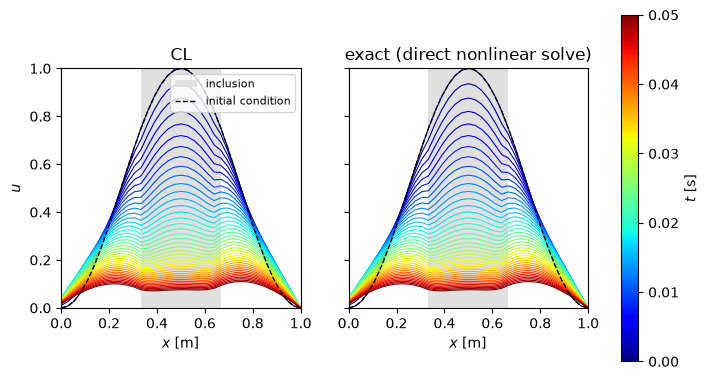

In [11]:
xp = np.concatenate([x, [1.0]])  # close the domain with the right Dirichlet node
fig, axes = plt.subplots(1, 2, figsize=(8.5, 4.5), sharey=True)
for ax, data, title in ((axes[0], cl, "CL"), (axes[1], exact, "exact (direct nonlinear solve)")):
    ax.axvspan(box[0][0] / n, (box[0][1] + 1) / n, color="0.88", lw=0, label="inclusion")
    for a, t in enumerate(times):
        ax.plot(xp, np.concatenate([data[a], [0.0]]), color=cm.jet(t / T), lw=0.8)
    ax.plot(xp, np.concatenate([u0, [0.0]]), "k--", lw=1.0, label="initial condition")
    ax.set(xlabel="$x$ [m]", xlim=(0, 1), ylim=(0, 1.0), title=title)
    ax.set_box_aspect(1)  # square panels
axes[0].set_ylabel(r"$u$")
axes[0].legend(loc="upper right", fontsize=8)
fig.colorbar(cm.ScalarMappable(cmap=cm.jet, norm=plt.Normalize(0, T)), ax=axes, label="$t$ [s]")
plt.show()

---

[← KPP–Fisher in 2-D](kpp_fisher_2d.ipynb) · [Notebook index](../README.md) · [Position-dependent, 2-D →](kpp_fisher_position_dependent_2d.ipynb)